# 1. Preparación y carga de datos

En este notebook analizaremos la relación comercial de COMPLEX SOLUTIONS S.L. con sus clientes.

El objetivo es conocer el perfil de la cartera de clientes, estudiar su evolución, analizar sus hábitos de compra y evaluar el valor económico que aportan a la empresa.

Para ello, utilizaremos información procedente de las tablas de clientes, ventas y detalle de ventas de la base de datos.

In [58]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv()

DB_NAME = os.getenv("POSTGRES_DB")
DB_USER = os.getenv("POSTGRES_USER")
DB_PASSWORD = os.getenv("POSTGRES_PASSWORD")
DB_HOST = "localhost"
DB_PORT = os.getenv("POSTGRES_PORT")

In [59]:
engine = create_engine(
    f"postgresql+psycopg://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

with engine.connect() as connection:
    result = connection.exec_driver_sql(
        "SELECT current_database(), current_user;"
    ).fetchone()

print("Conexión establecida correctamente.")
print("Base de datos:", result[0])
print("Usuario:", result[1])

Conexión establecida correctamente.
Base de datos: complex_solutions
Usuario: complex_admin


In [60]:
customers_df = pd.read_sql("SELECT * FROM customers;", engine)
sales_df = pd.read_sql("SELECT * FROM sales;", engine)
sale_items_df = pd.read_sql("SELECT * FROM sale_items;", engine)

print("Clientes:", customers_df.shape)
print("Ventas:", sales_df.shape)
print("Detalle de ventas:", sale_items_df.shape)

Clientes: (362, 9)
Ventas: (2101, 6)
Detalle de ventas: (2101, 7)



## 2. Inspección inicial de los datos

Antes de comenzar el análisis, revisaremos la estructura de las tablas y sus columnas.

Esta comprobación nos permitirá identificar qué información tenemos disponible y qué indicadores podemos calcular de forma fiable.

In [61]:
# Revisar primeros registros
display(customers_df.head())
display(sales_df.head())
display(sale_items_df.head())

,customer_id,customer_type,company_name,customer_segment,city,province,signup_date,acquisition_channel,sales_rep_id
0,1,B2B,Customer 00001,SMB,Madrid,Madrid,2026-09-08,OUTBOUND_SALES,1.0
1,2,B2C,Customer 00002,CONSUMER,Barcelona,Barcelona,2020-09-17,ONLINE,NaN
2,3,B2C,Customer 00003,CONSUMER,Valencia,Valencia,2024-04-25,ONLINE,NaN
3,4,B2B,Customer 00004,SMB,Sevilla,Sevilla,2024-04-12,OUTBOUND_SALES,1.0
4,5,B2C,Customer 00005,CONSUMER,Bilbao,Bizkaia,2026-09-06,ONLINE,NaN


,sale_id,customer_id,employee_id,sale_date,channel,status
0,1,177,1,2026-11-06,PHYSICAL_STORE,CONFIRMED
1,2,317,1,2024-06-12,ONLINE,CONFIRMED
2,3,55,1,2026-06-30,B2B,CONFIRMED
3,4,345,1,2025-06-10,ONLINE,CONFIRMED
4,5,166,1,2025-08-22,B2B,CONFIRMED


,sale_item_id,sale_id,product_id,quantity,unit_price,discount,unit_cost
0,1,1,8,2,458.70,0.0534,462.04
1,2,2,3,2,68.97,0.0518,61.10
2,3,3,12,2,1310.76,0.2107,1100.24
3,4,4,118,2,309.38,0.0386,245.25
4,5,5,28,3,1419.99,0.2015,1082.37


In [62]:
# Mostrar columnas de cada tabla

print("COLUMNAS DE CLIENTES:")
print(customers_df.columns.tolist())

print("\nCOLUMNAS DE VENTAS:")
print(sales_df.columns.tolist())

print("\nCOLUMNAS DEL DETALLE DE VENTAS:")
print(sale_items_df.columns.tolist())

COLUMNAS DE CLIENTES:
['customer_id', 'customer_type', 'company_name', 'customer_segment', 'city', 'province', 'signup_date', 'acquisition_channel', 'sales_rep_id']

COLUMNAS DE VENTAS:
['sale_id', 'customer_id', 'employee_id', 'sale_date', 'channel', 'status']

COLUMNAS DEL DETALLE DE VENTAS:
['sale_item_id', 'sale_id', 'product_id', 'quantity', 'unit_price', 'discount', 'unit_cost']


## 3. Calidad y relaciones entre los datos

Antes de analizar el comportamiento comercial, comprobaremos la integridad de la información.

Es necesario verificar que las ventas estén correctamente asociadas a los clientes y que los identificadores y fechas permitan realizar los análisis posteriores sin introducir errores.

In [63]:
# Comprobar identificadores y relaciones entre tablas

print("CLIENTES")
print("IDs duplicados:", customers_df["customer_id"].duplicated().sum())
print("IDs nulos:", customers_df["customer_id"].isna().sum())

print("\nVENTAS")
print("IDs de venta duplicados:", sales_df["sale_id"].duplicated().sum())
print("Clientes nulos:", sales_df["customer_id"].isna().sum())

print("\nDETALLE DE VENTAS")
print("IDs de detalle duplicados:", sale_items_df["sale_item_id"].duplicated().sum())
print("Ventas nulas:", sale_items_df["sale_id"].isna().sum())

CLIENTES
IDs duplicados: 0
IDs nulos: 0

VENTAS
IDs de venta duplicados: 0
Clientes nulos: 0

DETALLE DE VENTAS
IDs de detalle duplicados: 0
Ventas nulas: 0


In [64]:
# Identificar ventas sin cliente asociado
sales_without_customer_df = sales_df[
    ~sales_df["customer_id"].isin(customers_df["customer_id"])
]

# Identificar detalles sin venta asociada
items_without_sale_df = sale_items_df[
    ~sale_items_df["sale_id"].isin(sales_df["sale_id"])
]

print("Ventas sin cliente asociado:", len(sales_without_customer_df))
print("Detalles sin venta asociada:", len(items_without_sale_df))

Ventas sin cliente asociado: 0
Detalles sin venta asociada: 0


In [65]:
# Convertir fechas al formato datetime
customers_df["signup_date"] = pd.to_datetime(
    customers_df["signup_date"],
    errors="coerce"
)

sales_df["sale_date"] = pd.to_datetime(
    sales_df["sale_date"],
    errors="coerce"
)

print("Fechas de alta nulas:", customers_df["signup_date"].isna().sum())
print("Fechas de venta nulas:", sales_df["sale_date"].isna().sum())

print("\nPeriodo de altas:")
print(customers_df["signup_date"].min(), "→", customers_df["signup_date"].max())

print("\nPeriodo de ventas:")
print(sales_df["sale_date"].min(), "→", sales_df["sale_date"].max())

Fechas de alta nulas: 0
Fechas de venta nulas: 0

Periodo de altas:
2020-01-03 00:00:00 → 2026-11-26 00:00:00

Periodo de ventas:
2020-01-15 00:00:00 → 2026-12-20 00:00:00


### Conclusiones

No se detectan registros duplicados, identificadores nulos ni relaciones incorrectas entre clientes, ventas y detalles de ventas.

Tampoco se han encontrado fechas de alta o venta nulas.

Por lo que, podemos utilizar estas tablas para desarrollar el análisis de clientes y relaciones comerciales sin necesidad de realizar correcciones sobre los identificadores o las fechas comprobadas.

Se observa que en los datos, existen registros hasta diciembre de 2026. Al tratarse de datos simulados, tendremos esta circunstancia en cuenta durante la interpretación de los resultados.

## 4. Perfil de la cartera de clientes

### 4.1. Distribución por tipo de cliente

Analizaremos la composición de la cartera según el tipo de cliente, diferenciando entre empresas (B2B) y particulares (B2C).

Esta distribución permitirá conocer qué tipo de cliente tiene mayor presencia en la cartera comercial de la empresa.

In [66]:
# Distribución de clientes por tipo

customer_type_df = (
    customers_df["customer_type"]
    .value_counts()
    .reset_index()
)

customer_type_df.columns = ["customer_type", "total_customers"]

customer_type_df["percentage"] = (
    customer_type_df["total_customers"]
    / customer_type_df["total_customers"].sum() * 100
)

customer_type_df

,customer_type,total_customers,percentage
0,B2C,240,66.298343
1,B2B,122,33.701657


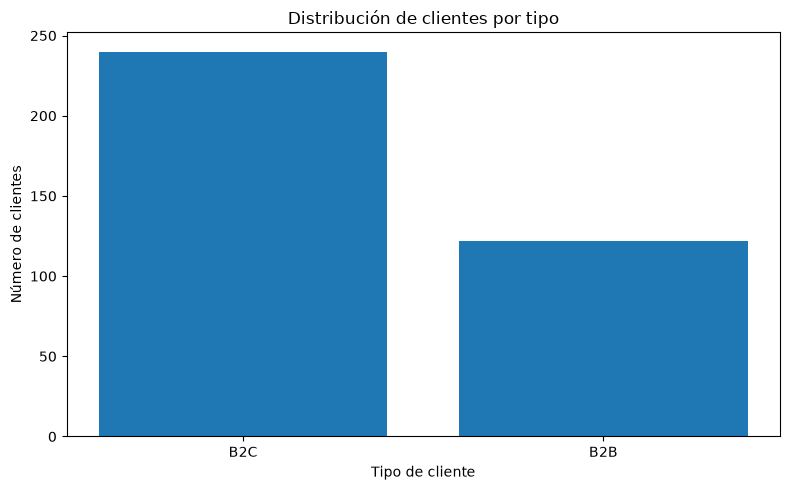

In [67]:
plt.figure(figsize=(8, 5))

plt.bar(
    customer_type_df["customer_type"],
    customer_type_df["total_customers"]
)

plt.title("Distribución de clientes por tipo")
plt.xlabel("Tipo de cliente")
plt.ylabel("Número de clientes")

plt.tight_layout()
plt.show()

### 4.2. Distribución por segmento

Estudiaremos cómo se distribuyen los clientes entre los distintos segmentos comerciales definidos por la empresa.

Esto permitirá identificar qué perfiles tienen mayor presencia dentro de la cartera.

In [68]:
customer_segment_df = (
    customers_df
    .groupby(["customer_type", "customer_segment"])
    .size()
    .reset_index(name="total_customers")
)

customer_segment_df

,customer_type,customer_segment,total_customers
0,B2B,SMB,122
1,B2C,CONSUMER,240


### 4.3. Distribución geográfica de los clientes

Analizaremos la distribución territorial de los clientes para identificar las provincias con mayor concentración de la cartera comercial.

Esta información puede ayudar a detectar zonas con mayor presencia comercial y posibles oportunidades de expansión.

In [69]:
customer_province_df = (
    customers_df
    .groupby("province")
    .size()
    .reset_index(name="total_customers")
    .sort_values("total_customers", ascending=False)
)

customer_province_df["percentage"] = (
    customer_province_df["total_customers"]
    / customer_province_df["total_customers"].sum() * 100
)

customer_province_df

,province,total_customers,percentage
2,Madrid,61,16.850829
4,Valencia,61,16.850829
0,Barcelona,60,16.574586
1,Bizkaia,60,16.574586
3,Sevilla,60,16.574586
5,Zaragoza,60,16.574586


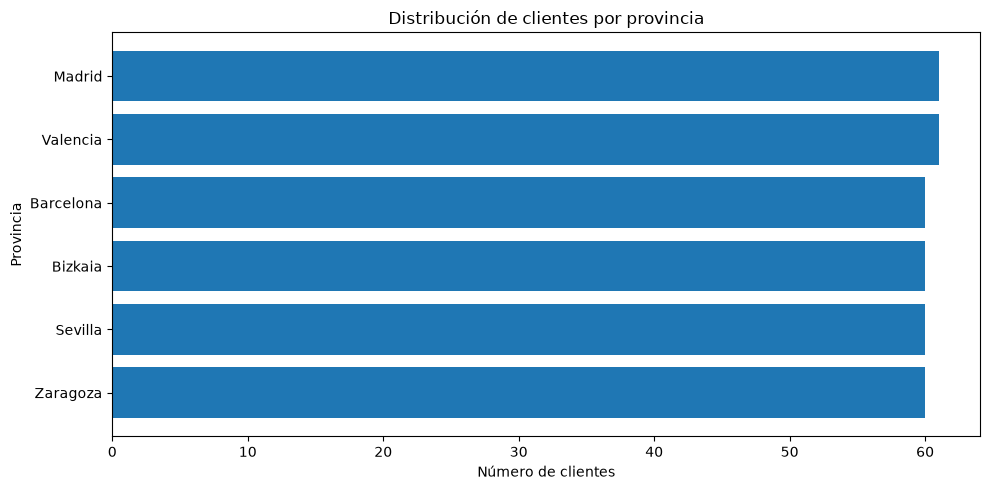

In [70]:
plt.figure(figsize=(10, 5))

plt.barh(
    customer_province_df["province"],
    customer_province_df["total_customers"]
)

plt.title("Distribución de clientes por provincia")
plt.xlabel("Número de clientes")
plt.ylabel("Provincia")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Conclusiones

La cartera comercial está formada por 362 clientes, de los cuales el 66,30 % son particulares (B2C) y el 33,70 % empresas (B2B).

La segmentación comercial coincide con el tipo de cliente: los particulares pertenecen al segmento CONSUMER y las empresas al segmento SMB.

Desde el punto de vista geográfico, la distribución es muy equilibrada entre las seis provincias analizadas, sin que exista una concentración territorial significativa.

Estos resultados describen la composición de la cartera, pero todavía no permiten determinar qué tipo de cliente aporta mayor facturación ni cuáles mantienen una relación comercial más activa.

## 5. Captación y evolución de clientes

### 5.1. Evolución anual de nuevas altas

Analizaremos el número de clientes incorporados a la cartera cada año, utilizando su fecha de registro.

El objetivo es conocer la evolución de la captación y detectar posibles cambios en el ritmo de crecimiento de la empresa.

In [71]:
# Crear una columna con el año de alta
customers_df["signup_year"] = customers_df["signup_date"].dt.year

# Calcular nuevas altas por año
customer_acquisition_df = (
    customers_df
    .groupby("signup_year")
    .size()
    .reset_index(name="new_customers")
    .sort_values("signup_year")
)

customer_acquisition_df

,signup_year,new_customers
0,2020,56
1,2021,52
2,2022,63
3,2023,46
4,2024,49
5,2025,42
6,2026,54


### 5.2. Evolución de la captación por tipo de cliente

Desglosaremos las nuevas altas anuales según el tipo de cliente.

Esta comparación permitirá identificar si la captación de empresas y particulares sigue una evolución similar o presenta diferencias.

In [72]:
customer_acquisition_type_df = (
    customers_df
    .groupby(["signup_year", "customer_type"])
    .size()
    .unstack(fill_value=0)
)

customer_acquisition_type_df

customer_type,B2B,B2C
signup_year,,
2020,23,33
2021,16,36
2022,20,43
2023,16,30
2024,12,37
2025,16,26
2026,19,35


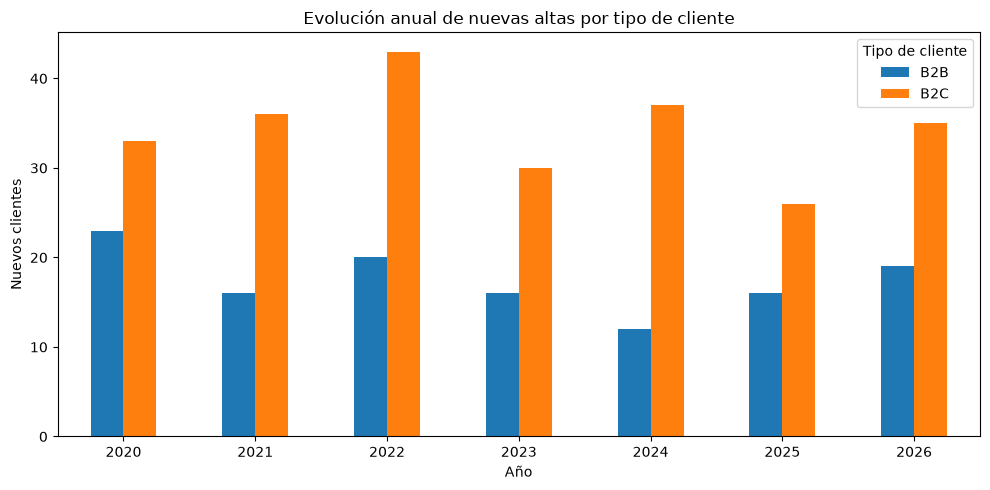

In [73]:
customer_acquisition_type_df.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Evolución anual de nuevas altas por tipo de cliente")
plt.xlabel("Año")
plt.ylabel("Nuevos clientes")
plt.xticks(rotation=0)
plt.legend(title="Tipo de cliente")

plt.tight_layout()
plt.show()

### Conclusiones

La empresa ha incorporado 362 clientes entre 2020 y 2026. El mayor volumen de captación se produjo en 2022, con 63 nuevas altas.

A partir de 2023 se observa una reducción del ritmo de incorporación de clientes, especialmente en 2025, cuando se registraron 42 altas.

En 2026 aparecen 54 nuevas altas, lo que supone una recuperación respecto al ejercicio anterior. Sin embargo, este resultado debe interpretarse teniendo en cuenta que el conjunto de datos incluye fechas simuladas posteriores a la fecha actual.

Los clientes B2C representan la mayor parte de las nuevas incorporaciones durante todo el periodo analizado.

## 6. Recurrencia y fidelización de clientes

### 6.1. Frecuencia de compra por cliente

Analizaremos el número de compras realizadas por cada cliente durante el periodo disponible.

El objetivo es diferenciar entre clientes con una única compra y clientes recurrentes, identificando el grado de actividad comercial de la cartera.

In [74]:
# Calcular el número de compras por cliente

customer_purchase_frequency_df = (
    sales_df
    .groupby("customer_id")
    .agg(
        total_purchases=("sale_id", "nunique"),
        first_purchase=("sale_date", "min"),
        last_purchase=("sale_date", "max")
    )
    .reset_index()
)

# Incorporar clientes sin compras registradas
customer_purchase_frequency_df = (
    customers_df[["customer_id", "customer_type"]]
    .merge(
        customer_purchase_frequency_df,
        on="customer_id",
        how="left"
    )
)

customer_purchase_frequency_df["total_purchases"] = (
    customer_purchase_frequency_df["total_purchases"]
    .fillna(0)
    .astype(int)
)

customer_purchase_frequency_df.head()

,customer_id,customer_type,total_purchases,first_purchase,last_purchase
0,1,B2B,2,2026-11-01,2026-12-16
1,2,B2C,12,2020-12-12,2026-03-13
2,3,B2C,2,2024-11-04,2026-04-01
3,4,B2B,1,2026-11-26,2026-11-26
4,5,B2C,2,2026-10-05,2026-12-04


### 6.2. Clasificación de clientes según su recurrencia

Clasificaremos a los clientes según el número de compras registradas.

Esta clasificación permitirá conocer qué proporción de la cartera mantiene una actividad comercial repetida y qué parte todavía no ha generado compras o únicamente ha realizado una operación.

In [75]:
# Clasificar clientes según su frecuencia de compra

customer_purchase_frequency_df["purchase_category"] = np.select(
    [
        customer_purchase_frequency_df["total_purchases"] == 0,
        customer_purchase_frequency_df["total_purchases"] == 1
    ],
    [
        "Sin compras",
        "Una compra"
    ],
    default="Recurrente"
)

# Resumen de clientes por categoría
customer_recurrence_df = (
    customer_purchase_frequency_df["purchase_category"]
    .value_counts()
    .reset_index()
)

customer_recurrence_df.columns = [
    "purchase_category",
    "total_customers"
]

customer_recurrence_df["percentage"] = (
    customer_recurrence_df["total_customers"]
    / len(customers_df) * 100
)

customer_recurrence_df

,purchase_category,total_customers,percentage
0,Recurrente,317,87.569061
1,Una compra,31,8.563536
2,Sin compras,14,3.867403


### 6.3. Comparación de recurrencia entre B2B y B2C

Compararemos la frecuencia de compra según el tipo de cliente.

El análisis permitirá comprobar si las empresas presentan un comportamiento de compra más recurrente que los particulares o si ambos grupos mantienen patrones similares.

In [76]:
customer_recurrence_type_df = (
    customer_purchase_frequency_df
    .groupby(["customer_type", "purchase_category"])
    .size()
    .unstack(fill_value=0)
)

customer_recurrence_type_df

purchase_category,Recurrente,Sin compras,Una compra
customer_type,,,
B2B,105,8,9
B2C,212,6,22


### Conclusiones

El análisis muestra que en total, 317 de los 362 clientes registrados han realizado al menos dos compras, lo que representa un 87,57 % de la cartera.

Por tipo de cliente, la recurrencia alcanza el 86,07 % en B2B y el 88,33 % en B2C. Los resultados muestran un comportamiento similar entre ambos grupos de clientes.

También se identifican 31 clientes con una única compra y 14 que no registran ninguna operación.

Estos últimos grupos merecen atención comercial, aunque para determinar si existe riesgo de pérdida de clientes será necesario analizar cuándo realizaron su última compra.

## 7. Actividad reciente de los clientes

### 7.1. Tiempo transcurrido desde la última compra

Analizaremos el tiempo transcurrido desde la última compra de cada cliente.

Este indicador permitirá identificar clientes con actividad reciente y aquellos que llevan más tiempo sin realizar operaciones.

Para evitar clasificaciones arbitrarias, utilizaremos como referencia la fecha máxima de venta disponible en el conjunto de datos.

In [77]:
# Obtener la última fecha de venta del conjunto de datos
reference_date = sales_df["sale_date"].max()

# Calcular los días desde la última compra
customer_purchase_frequency_df["days_since_last_purchase"] = (
    reference_date -
    customer_purchase_frequency_df["last_purchase"]
).dt.days

print("Fecha de referencia:", reference_date)

Fecha de referencia: 2026-12-20 00:00:00


### 7.2. Clasificación de clientes según su actividad

Agruparemos los clientes según el tiempo transcurrido desde su última compra.

Esta clasificación permitirá identificar diferentes niveles de actividad comercial y detectar clientes que podrían requerir seguimiento.

In [78]:
customer_purchase_frequency_df["activity_status"] = np.select(
    [
        customer_purchase_frequency_df["total_purchases"] == 0,
        customer_purchase_frequency_df["days_since_last_purchase"] <= 90,
        customer_purchase_frequency_df["days_since_last_purchase"] <= 180,
        customer_purchase_frequency_df["days_since_last_purchase"] <= 365
    ],
    [
        "Sin compras",
        "Actividad reciente",
        "Actividad moderada",
        "Actividad baja"
    ],
    default="Sin actividad reciente"
)

customer_activity_df = (
    customer_purchase_frequency_df["activity_status"]
    .value_counts()
    .reset_index()
)

customer_activity_df.columns = [
    "activity_status",
    "total_customers"
]

customer_activity_df["percentage"] = (
    customer_activity_df["total_customers"]
    / len(customers_df) * 100
)

customer_activity_df

,activity_status,total_customers,percentage
0,Actividad reciente,122,33.701657
1,Actividad moderada,81,22.375691
2,Actividad baja,80,22.099448
3,Sin actividad reciente,65,17.955801
4,Sin compras,14,3.867403


### Conclusiones

El análisis de actividad comercial muestra que 122 clientes (33,70 %) realizaron su última compra durante los últimos 90 días respecto a la fecha de referencia utilizada.

Por otro lado, 65 clientes (17,96 %) llevan más de un año sin realizar compras, mientras que otros 80 presentan una inactividad de entre seis meses y un año.

Estos resultados permiten identificar un grupo de clientes que podría requerir acciones de seguimiento comercial, especialmente aquellos que acumulan periodos prolongados sin actividad.

La clasificación se ha realizado tomando como referencia la última fecha de venta disponible en el conjunto de datos (20 de diciembre de 2026). Al tratarse de datos simulados, los resultados deben interpretarse como parte de un escenario ficticio.

### 7.3. Comparación de actividad comercial por tipo de cliente

Compararemos los niveles de actividad de los clientes B2B y B2C para identificar posibles diferencias en su comportamiento comercial.

El objetivo es determinar si alguno de los dos segmentos concentra una mayor proporción de clientes con periodos prolongados sin compras.

In [79]:
# Distribución de actividad por tipo de cliente

customer_activity_type_df = (
    customer_purchase_frequency_df
    .groupby(["customer_type", "activity_status"])
    .size()
    .unstack(fill_value=0)
)

# Calcular porcentajes dentro de cada tipo de cliente
customer_activity_type_pct_df = (
    customer_activity_type_df
    .div(customer_activity_type_df.sum(axis=1), axis=0)
    * 100
)

customer_activity_type_pct_df.round(2)

activity_status,Actividad baja,Actividad moderada,Actividad reciente,Sin actividad reciente,Sin compras
customer_type,,,,,
B2B,18.03,25.41,31.97,18.03,6.56
B2C,24.17,20.83,34.58,17.92,2.50


### Conclusiones

La comparación entre clientes B2B y B2C muestra patrones de actividad relativamente similares.

Los clientes B2C presentan un porcentaje ligeramente superior de actividad reciente (34,58 % frente al 31,97 % de B2B). Sin embargo, también concentran una mayor proporción de clientes con actividad baja.

Por su parte, el segmento B2B presenta un porcentaje superior de clientes sin compras registradas (6,56 % frente al 2,50 % de B2C).

La proporción de clientes sin actividad durante más de un año es prácticamente idéntica en ambos segmentos.

Estos resultados no permiten identificar diferencias contundentes en la actividad comercial, aunque sí señalan oportunidades de seguimiento en ambos grupos.

## 8. Análisis del valor económico de los clientes

### 8.1. Preparación del conjunto de datos

Para analizar la contribución económica de cada cliente, combinaremos la información de clientes, ventas y detalle de ventas.

Calcularemos los ingresos, costes y beneficio bruto de las operaciones, obteniendo una visión económica consolidada de cada cliente.

In [80]:
# Unir ventas con el detalle de sus líneas
sales_detail_df = sales_df.merge(
    sale_items_df,
    on="sale_id",
    how="inner"
)

# Incorporar la información de los clientes
customer_sales_df = sales_detail_df.merge(
    customers_df[
        ["customer_id", "customer_type", "customer_segment", "company_name"]
    ],
    on="customer_id",
    how="left"
)

# Calcular magnitudes económicas
customer_sales_df["revenue"] = (
    customer_sales_df["quantity"]
    * customer_sales_df["unit_price"]
    * (1 - customer_sales_df["discount"])
)

customer_sales_df["total_cost"] = (
    customer_sales_df["quantity"]
    * customer_sales_df["unit_cost"]
)

customer_sales_df["gross_profit"] = (
    customer_sales_df["revenue"]
    - customer_sales_df["total_cost"]
)

print("Registros:", customer_sales_df.shape[0])
print("Ventas únicas:", customer_sales_df["sale_id"].nunique())
print("Clientes únicos:", customer_sales_df["customer_id"].nunique())

print("\nIngresos totales:", round(customer_sales_df["revenue"].sum(), 2))
print("Costes totales:", round(customer_sales_df["total_cost"].sum(), 2))
print("Beneficio bruto:", round(customer_sales_df["gross_profit"].sum(), 2))

Registros: 2101
Ventas únicas: 2101
Clientes únicos: 348

Ingresos totales: 2269624.61
Costes totales: 2112374.6
Beneficio bruto: 157250.01


### 8.2. Valor económico por cliente

Agruparemos las operaciones comerciales por cliente para calcular su contribución económica acumulada.

Analizaremos el número de compras, las unidades adquiridas, los ingresos, los costes y el beneficio bruto generado por cada cliente.

Esto permitirá identificar qué clientes aportan mayor volumen de negocio y cuáles generan una mayor contribución económica.

In [81]:
# Calcular indicadores económicos por cliente

customer_value_df = (
    customer_sales_df
    .groupby(["customer_id", "customer_type", "company_name"])
    .agg(
        total_purchases=("sale_id", "nunique"),
        units_purchased=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

# Calcular margen bruto
customer_value_df["gross_margin_pct"] = (
    customer_value_df["gross_profit"]
    / customer_value_df["revenue"] * 100
)

# Incorporar también los clientes sin compras
customer_value_df = (
    customers_df[
        ["customer_id", "customer_type", "company_name"]
    ]
    .merge(
        customer_value_df.drop(
            columns=["customer_type", "company_name"]
        ),
        on="customer_id",
        how="left"
    )
)

# Sustituir valores nulos de clientes sin operaciones
numeric_columns = [
    "total_purchases",
    "units_purchased",
    "revenue",
    "total_cost",
    "gross_profit"
]

customer_value_df[numeric_columns] = (
    customer_value_df[numeric_columns].fillna(0)
)

customer_value_df[numeric_columns] = (
    customer_value_df[numeric_columns].astype(
        {"total_purchases": int, "units_purchased": int}
    )
)

customer_value_df["gross_margin_pct"] = (
    customer_value_df["gross_margin_pct"].fillna(0)
)

print("Clientes analizados:", len(customer_value_df))
print("Clientes con compras:", (customer_value_df["total_purchases"] > 0).sum())
print("Clientes sin compras:", (customer_value_df["total_purchases"] == 0).sum())

display(customer_value_df.head())

Clientes analizados: 362
Clientes con compras: 348
Clientes sin compras: 14


,customer_id,customer_type,company_name,total_purchases,units_purchased,revenue,total_cost,gross_profit,gross_margin_pct
0,1,B2B,Customer 00001,2,4,2720.311828,2823.20,-102.888172,-3.782220
1,2,B2C,Customer 00002,12,19,10637.472914,8638.67,1998.802914,18.790204
2,3,B2C,Customer 00003,2,3,698.816964,720.40,-21.583036,-3.088511
3,4,B2B,Customer 00004,1,2,46.772000,55.40,-8.628000,-18.446934
4,5,B2C,Customer 00005,2,5,1707.717468,1601.04,106.677468,6.246787


### 8.3. Ranking de clientes por beneficio bruto

Identificaremos los diez clientes que generan una mayor contribución al beneficio bruto de la empresa.

Este ranking permitirá reconocer las relaciones comerciales con mayor aportación económica, teniendo en cuenta tanto el volumen de ingresos como los costes asociados.

In [82]:
# Seleccionar los 10 clientes con mayor beneficio bruto

top_10_customers_df = (
    customer_value_df
    .sort_values("gross_profit", ascending=False)
    .head(10)
    [[
        "customer_id",
        "customer_type",
        "company_name",
        "total_purchases",
        "revenue",
        "gross_profit",
        "gross_margin_pct"
    ]]
    .reset_index(drop=True)
)

top_10_customers_df.round(2)

,customer_id,customer_type,company_name,total_purchases,revenue,gross_profit,gross_margin_pct
0,249,B2C,Customer 00249,17,26787.91,4093.54,15.28
1,93,B2C,Customer 00093,9,22361.65,3889.08,17.39
2,293,B2C,Customer 00293,17,29982.37,3746.61,12.50
3,207,B2C,Customer 00207,16,30601.65,2961.42,9.68
4,261,B2C,Customer 00261,15,15495.91,2916.97,18.82
5,290,B2C,Customer 00290,11,24362.19,2671.84,10.97
6,258,B2C,Customer 00258,10,17328.88,2342.03,13.52
7,348,B2C,Customer 00348,7,13141.71,2324.18,17.69
8,42,B2C,Customer 00042,9,17419.65,2277.71,13.08
9,171,B2C,Customer 00171,14,15872.35,2220.15,13.99


### 8.4. Ranking de clientes por ingresos

Identificaremos los diez clientes con mayor volumen de ingresos y compararemos su posición con el ranking de beneficio bruto.

El objetivo es comprobar si los clientes que más facturación aportan son también los que generan una mayor rentabilidad.

In [83]:
# Seleccionar los 10 clientes con mayores ingresos

top_10_revenue_customers_df = (
    customer_value_df
    .sort_values("revenue", ascending=False)
    .head(10)
    [[
        "customer_id",
        "customer_type",
        "company_name",
        "total_purchases",
        "revenue",
        "gross_profit",
        "gross_margin_pct"
    ]]
    .reset_index(drop=True)
)

top_10_revenue_customers_df.round(2)

,customer_id,customer_type,company_name,total_purchases,revenue,gross_profit,gross_margin_pct
0,207,B2C,Customer 00207,16,30601.65,2961.42,9.68
1,293,B2C,Customer 00293,17,29982.37,3746.61,12.50
2,249,B2C,Customer 00249,17,26787.91,4093.54,15.28
3,307,B2B,Customer 00307,19,24749.94,2094.88,8.46
4,290,B2C,Customer 00290,11,24362.19,2671.84,10.97
5,93,B2C,Customer 00093,9,22361.65,3889.08,17.39
6,154,B2B,Customer 00154,13,22305.41,66.43,0.30
7,69,B2C,Customer 00069,10,20412.29,1996.09,9.78
8,251,B2C,Customer 00251,9,18688.34,1594.88,8.53
9,178,B2B,Customer 00178,12,18316.63,325.04,1.77


### 9. Clientes con menor rentabilidad

Analizaremos los clientes con menor beneficio bruto acumulado para identificar relaciones comerciales que podrían estar comprometiendo la rentabilidad de la empresa.

Este análisis permitirá detectar cuentas con resultados negativos o márgenes especialmente reducidos y valorar si requieren una revisión de sus condiciones comerciales.

In [84]:
# Identificar los 10 clientes con menor beneficio bruto acumulado
bottom_10_customers_df = (
    customer_value_df[
        customer_value_df["total_purchases"] > 0
    ]
    .sort_values("gross_profit")
    .head(10)
    .reset_index(drop=True)
)

bottom_10_customers_df[
    [
        "customer_id",
        "customer_type",
        "company_name",
        "total_purchases",
        "revenue",
        "gross_profit",
        "gross_margin_pct"
    ]
]

,customer_id,customer_type,company_name,total_purchases,revenue,gross_profit,gross_margin_pct
0,295,B2B,Customer 00295,9,14021.095012,-1355.834988,-9.669965
1,49,B2B,Customer 00049,5,7729.695237,-1073.264763,-13.884956
2,34,B2B,Customer 00034,3,5206.921170,-887.108830,-17.037109
3,73,B2B,Customer 00073,10,13852.025961,-768.464039,-5.547665
4,22,B2B,Customer 00022,4,7017.914259,-662.635741,-9.442061
5,292,B2B,Customer 00292,3,8384.526003,-650.113997,-7.753736
6,199,B2B,Customer 00199,6,5504.820532,-632.029468,-11.481382
7,259,B2B,Customer 00259,4,5227.429968,-626.730032,-11.989257
8,67,B2B,Customer 00067,4,3281.500934,-578.709066,-17.635499
9,352,B2B,Customer 00352,6,5033.724470,-575.915530,-11.441141


### 10. Comparativa de rentabilidad: B2B vs. B2C

Compararemos los resultados económicos de los dos segmentos de clientes para evaluar su contribución a la facturación y al beneficio bruto de la empresa.

Analizaremos el número de clientes, las compras realizadas, los ingresos, el beneficio bruto y el margen obtenido por cada segmento.

In [87]:
# Comparar la rentabilidad por tipo de cliente
customer_type_profitability_df = (
    customer_value_df[
        customer_value_df["total_purchases"] > 0
    ]
    .groupby("customer_type")
    .agg(
        total_customers=("customer_id", "nunique"),
        total_purchases=("total_purchases", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

customer_type_profitability_df["gross_margin_pct"] = (
    customer_type_profitability_df["gross_profit"]
    / customer_type_profitability_df["revenue"] * 100
)

customer_type_profitability_df

,customer_type,total_customers,total_purchases,revenue,total_cost,gross_profit,gross_margin_pct
0,B2B,114,684,6.690412e+05,677672.99,-8631.763663,-1.290169
1,B2C,234,1417,1.600583e+06,1434701.61,165881.771322,10.363832


## 11. Concentración de ingresos por cliente

Analizamos cómo se distribuyen los ingresos entre los clientes para identificar posibles dependencias comerciales. El objetivo es determinar qué porcentaje de la facturación procede de los principales clientes y evaluar el riesgo asociado a una elevada concentración de ingresos.

In [88]:
# Preparar el análisis de concentración de ingresos por cliente

customer_revenue_concentration_df = (
    customer_value_df[
        customer_value_df["total_purchases"] > 0
    ]
    [["customer_id", "customer_type", "company_name", "revenue"]]
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)

# Calcular la posición de cada cliente en el ranking
customer_revenue_concentration_df["customer_rank"] = (
    range(1, len(customer_revenue_concentration_df) + 1)
)

# Calcular el porcentaje de ingresos de cada cliente
customer_revenue_concentration_df["revenue_pct"] = (
    customer_revenue_concentration_df["revenue"]
    / customer_revenue_concentration_df["revenue"].sum() * 100
)

# Calcular el porcentaje acumulado de ingresos
customer_revenue_concentration_df["cumulative_revenue_pct"] = (
    customer_revenue_concentration_df["revenue_pct"].cumsum()
)

# Calcular el porcentaje acumulado de clientes
customer_revenue_concentration_df["cumulative_customers_pct"] = (
    customer_revenue_concentration_df["customer_rank"]
    / len(customer_revenue_concentration_df) * 100
)

customer_revenue_concentration_df.head(10)

,customer_id,customer_type,company_name,revenue,customer_rank,revenue_pct,cumulative_revenue_pct,cumulative_customers_pct
0,207,B2C,Customer 00207,30601.650622,1,1.348313,1.348313,0.287356
1,293,B2C,Customer 00293,29982.370232,2,1.321028,2.669341,0.574713
2,249,B2C,Customer 00249,26787.909028,3,1.180279,3.849620,0.862069
3,307,B2B,Customer 00307,24749.939088,4,1.090486,4.940106,1.149425
4,290,B2C,Customer 00290,24362.189393,5,1.073402,6.013508,1.436782
5,93,B2C,Customer 00093,22361.651744,6,0.985258,6.998766,1.724138
6,154,B2B,Customer 00154,22305.409042,7,0.982780,7.981545,2.011494
7,69,B2C,Customer 00069,20412.289355,8,0.899369,8.880914,2.298851
8,251,B2C,Customer 00251,18688.339710,9,0.823411,9.704325,2.586207
9,178,B2B,Customer 00178,18316.629138,10,0.807033,10.511358,2.873563


## 12. Antigüedad y valor del cliente

En este apartado analizaremos si existe alguna relación entre el tiempo que un cliente lleva registrado en la empresa y el valor económico que ha generado.

Para ello, relacionaremos la fecha de alta de cada cliente con sus ingresos acumulados y calcularemos una referencia de ingresos mensuales desde su incorporación.

In [92]:
# Fecha de referencia: última fecha disponible de ventas
reference_date = sales_df["sale_date"].max()

# Agrupar las ventas para obtener métricas por cliente
customer_tenure_df = (
    customer_sales_df
    .groupby(
        [
            "customer_id",
            "customer_type",
            "company_name"
        ],
        as_index=False
    )
    .agg(
        total_purchases=("sale_id", "nunique"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

# Incorporar la fecha de alta
customer_tenure_df = customer_tenure_df.merge(
    customers_df[["customer_id", "signup_date"]],
    on="customer_id",
    how="left"
)

# Calcular antigüedad
customer_tenure_df["tenure_days"] = (
    reference_date - customer_tenure_df["signup_date"]
).dt.days

customer_tenure_df["tenure_months"] = (
    customer_tenure_df["tenure_days"] / 30.44
)

# Calcular ingresos medios mensuales desde el alta
customer_tenure_df["revenue_per_month"] = (
    customer_tenure_df["revenue"]
    / customer_tenure_df["tenure_months"].clip(lower=1)
)

customer_tenure_df.head()

,customer_id,customer_type,company_name,total_purchases,revenue,total_cost,gross_profit,signup_date,tenure_days,tenure_months,revenue_per_month
0,1,B2B,Customer 00001,2,2720.311828,2823.20,-102.888172,2026-09-08,103,3.383706,803.944583
1,2,B2C,Customer 00002,12,10637.472914,8638.67,1998.802914,2020-09-17,2285,75.065703,141.708830
2,3,B2C,Customer 00003,2,698.816964,720.40,-21.583036,2024-04-25,969,31.833114,21.952516
3,4,B2B,Customer 00004,1,46.772000,55.40,-8.628000,2024-04-12,982,32.260184,1.449837
4,5,B2C,Customer 00005,2,1707.717468,1601.04,106.677468,2026-09-06,105,3.449409,495.075426


In [93]:
customer_tenure_summary_df = (
    customer_tenure_df
    .groupby("customer_type")
    .agg(
        total_customers=("customer_id", "nunique"),
        avg_tenure_months=("tenure_months", "mean"),
        median_tenure_months=("tenure_months", "median"),
        avg_revenue=("revenue", "mean"),
        median_revenue=("revenue", "median"),
        avg_revenue_per_month=("revenue_per_month", "mean"),
        avg_gross_profit=("gross_profit", "mean")
    )
    .round(2)
    .reset_index()
)

customer_tenure_summary_df

,customer_type,total_customers,avg_tenure_months,median_tenure_months,avg_revenue,median_revenue,avg_revenue_per_month,avg_gross_profit
0,B2B,114,45.16,47.73,5868.78,5070.84,166.79,-75.72
1,B2C,234,43.59,45.25,6840.10,5835.61,180.64,708.90


## 13. Relación entre antigüedad y rentabilidad

Analizaremos si existe una relación entre el tiempo que un cliente lleva registrado en la empresa y el beneficio bruto acumulado que ha generado.

El objetivo es comprobar si los clientes con mayor antigüedad aportan necesariamente una mayor rentabilidad.

In [94]:
# Relación entre antigüedad y rentabilidad
customer_tenure_correlation = customer_tenure_df[
    ["tenure_months", "gross_profit"]
].corr()

customer_tenure_correlation

,tenure_months,gross_profit
tenure_months,1.0000,0.3472
gross_profit,0.3472,1.0000


## 14. Segmentación de clientes por valor y comportamiento

En este apartado agruparemos a los clientes según su contribución económica y su comportamiento de compra.

El objetivo es identificar perfiles comerciales diferenciados que permitan orientar las acciones de fidelización, desarrollo comercial y revisión de cuentas.

In [95]:
# Crear una copia de los datos de rentabilidad por cliente
customer_segmentation_df = customer_tenure_df.copy()

# Calcular umbrales de referencia
profit_threshold = customer_segmentation_df["gross_profit"].median()
purchases_threshold = customer_segmentation_df["total_purchases"].median()

# Clasificar clientes según rentabilidad y frecuencia de compra
def classify_customer(row):

    if row["gross_profit"] < 0:
        return "Cliente no rentable"

    elif (
        row["gross_profit"] >= profit_threshold
        and row["total_purchases"] >= purchases_threshold
    ):
        return "Alto valor"

    elif row["total_purchases"] >= purchases_threshold:
        return "Compra recurrente"

    else:
        return "Cliente con potencial"


customer_segmentation_df["customer_segment_analysis"] = (
    customer_segmentation_df.apply(
        classify_customer,
        axis=1
    )
)

customer_segmentation_df[
    [
        "customer_id",
        "customer_type",
        "total_purchases",
        "revenue",
        "gross_profit",
        "customer_segment_analysis"
    ]
].head(10)

,customer_id,customer_type,total_purchases,revenue,gross_profit,customer_segment_analysis
0,1,B2B,2,2720.311828,-102.888172,Cliente no rentable
1,2,B2C,12,10637.472914,1998.802914,Alto valor
2,3,B2C,2,698.816964,-21.583036,Cliente no rentable
3,4,B2B,1,46.772000,-8.628000,Cliente no rentable
4,5,B2C,2,1707.717468,106.677468,Cliente con potencial
5,6,B2C,2,5120.193528,-116.166472,Cliente no rentable
6,7,B2B,2,2305.149101,186.609101,Cliente con potencial
7,8,B2C,5,5623.330958,524.470958,Cliente con potencial
8,9,B2C,3,2332.195821,-3.484179,Cliente no rentable
9,10,B2B,8,10930.370770,687.460770,Alto valor


# 12. Conclusiones del análisis de clientes

Después de analizar la información de los clientes, sus compras, su actividad y su rentabilidad, podemos extraer varias conclusiones importantes sobre la situación comercial de COMPLEX SOLUTIONS S.L.

### 1. Distribución de la cartera de clientes

La empresa cuenta con 362 clientes registrados: 240 pertenecen al segmento B2C (66,30 %) y 122 al B2B (33,70 %).

La distribución geográfica está bastante equilibrada entre las seis provincias analizadas, con Madrid y Valencia a la cabeza, ambas con 61 clientes.

Esto indica que la empresa no depende de una única provincia para mantener su cartera de clientes.

### 2. Captación de nuevos clientes

Durante el periodo analizado se han registrado nuevas altas todos los años. El mayor número se produjo en 2022, con 63 nuevos clientes, mientras que 2025 fue el año con menos incorporaciones, con 42.

El segmento B2C aporta más clientes nuevos que el B2B en todos los años analizados.

Aunque existe una captación continuada, sería interesante seguir la evolución de estas altas para comprobar si se mantiene el ritmo de incorporación de nuevos clientes.

### 3. Frecuencia de compra y actividad

De los 362 clientes registrados, 348 han realizado al menos una compra y 14 todavía no han comprado.

Entre los clientes que han comprado, 317 han realizado compras recurrentes y 31 solamente han realizado una compra.

También observamos que 122 clientes presentan actividad reciente, mientras que 65 no han realizado compras recientes.

Estos datos muestran que la mayoría de la cartera ha comprado en más de una ocasión, aunque existe un grupo de clientes cuya actividad convendría revisar para conocer si han dejado de comprar o simplemente han reducido su frecuencia.

### 4. Diferencias entre clientes B2B y B2C

Uno de los resultados más importantes aparece al comparar la rentabilidad de ambos tipos de cliente.

- **B2B:** 114 clientes, unos ingresos aproximados de 669.041 € y un beneficio bruto negativo de -8.631,76 €. El margen bruto es del -1,29 %.
- **B2C:** 234 clientes, unos ingresos aproximados de 1.600.583 € y un beneficio bruto de 165.881,77 €. El margen bruto es del 10,36 %.

El segmento B2C presenta una rentabilidad claramente superior. Por el contrario, el segmento B2B genera ingresos importantes, pero actualmente está registrando pérdidas en conjunto.

Este resultado merece especial atención, ya que vender más no siempre significa ganar más dinero. La empresa debería revisar las condiciones comerciales y los costes asociados a sus clientes B2B.

### 5. Concentración de ingresos

El análisis de los diez clientes con mayores ingresos muestra que representan aproximadamente el 10,51 % de los ingresos totales.

Esto indica que los ingresos no dependen exclusivamente de un grupo muy reducido de clientes, sino que están repartidos entre una cartera más amplia.

Aun así, es importante mantener identificados a los clientes que más ingresos aportan y conocer su rentabilidad, ya que un cliente con una facturación elevada no tiene por qué ser necesariamente rentable.

### 6. Antigüedad y valor de los clientes

La antigüedad media de los clientes es bastante similar en ambos segmentos:

- B2B: 45,16 meses.
- B2C: 43,59 meses.

Sin embargo, encontramos diferencias importantes en el valor económico que aportan.

El ingreso medio por cliente es de aproximadamente 5.869 € en B2B y 6.840 € en B2C.

Si relacionamos los ingresos con los meses de antigüedad, el segmento B2C también presenta un resultado superior: 180,64 € mensuales frente a 166,79 € en B2B.

La antigüedad, por sí sola, no garantiza que un cliente sea rentable. De hecho, el segmento B2B tiene una antigüedad media ligeramente superior, pero presenta pérdidas en conjunto.

### 7. Clasificación de clientes

La clasificación realizada permite distinguir entre clientes de alto valor, clientes con potencial y clientes que actualmente no son rentables.

Esta información puede ayudar a la empresa a decidir dónde centrar sus esfuerzos comerciales:

- Mantener y cuidar a los clientes que aportan mayor beneficio.
- Estudiar cómo mejorar la relación con los clientes que tienen potencial.
- Revisar las condiciones de aquellos clientes que generan pérdidas.

La clasificación debe entenderse como una fotografía de la situación actual, no como una valoración definitiva del potencial futuro de cada cliente.

## Conclusión general

El análisis muestra que COMPLEX SOLUTIONS S.L. dispone de una cartera de clientes amplia y que la mayoría de ellos ha realizado compras recurrentes.

Sin embargo, existe una diferencia importante entre los segmentos B2B y B2C. Mientras que los clientes B2C generan un beneficio bruto positivo, el segmento B2B presenta pérdidas a pesar de aportar una facturación considerable.

Por tanto, uno de los principales puntos que debería revisar la empresa es la rentabilidad de sus clientes B2B. No se trata únicamente de conseguir más clientes o aumentar las ventas, sino de comprobar que las operaciones comerciales dejan un beneficio adecuado.

También sería conveniente realizar un seguimiento de los clientes que han reducido su actividad, mantener identificados a los clientes de mayor valor y revisar periódicamente la evolución de la cartera.

** La principal conclusión es que la empresa necesita prestar tanta atención a la rentabilidad de sus clientes como al volumen de ingresos que generan. **